In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/0
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '0' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))


# 第0章 OSって個人で作れるの？ — 0.4 OS自作の楽しみ方 (*How to Enjoy OS Development*)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/0/0.4_How_to_Enjoy_OS_Development.ipynb)

---

## 1. 導入：OS自作の最大の魅力と「挫折の壁」

自作OSの世界へ足を踏み入れた開発者が最初に味わう体験は、既存のどのようなアプリケーション開発とも異なります。

私たちが普段書いているWebアプリや機械学習プログラム、スマートフォンアプリは、すべて「OSという巨大で頑丈な防護壁と土台」の上で動いています。メモリの割り当て、CPUのスケジューリング、画面へのピクセル描画、ネットワーク通信のすべては、OSのシステムコール（*System Call*）や標準Cライブラリ（*libc*）が裏側で完璧に処理してくれているため、プログラマはハードウェアの泥臭い物理的挙動を意識する必要がありません。

しかし、自作OS（ベアメタルプログラミング）の世界では、**防護壁も安全ネットも一切存在しません**。
自分が書いたわずか数行の機械語やアセンブリコードが、CPUの命令ポインタ（`%rip`）を直接動かし、物理アドレス空間のレジスタ（MMIO: *Memory-Mapped I/O*）を叩き、ディスプレイのフレームバッファ（*FrameBuffer*）に直接光を灯します。
**「手元の物理的なシリコンの塊（PC）を、誰の許可も得ず、自分の書いたコードだけで100%意のままに支配している」** という万能感と圧倒的な知的好奇心の充足こそが、OS自作の最大の魅力です。

### 多くの挑戦者が直面する「挫折の壁」
一方で、OS自作はコンピュータサイエンスの中で最も挫折率が高い分野の一つとしても知られています。その原因は才能や知能の不足ではなく、**「開発手法の過ち」** と **「低レイヤ特有のデバッグ困難性」** にあります。

| 通常のアプリ開発 | ベアメタルOS自作初期の現実 |
|---|---|
| エラー箇所がスタックトレースや行番号で表示される | **画面が真っ黒のまま無言でハングアップ**する |
| `print()` や `std::cout` で変数の中身を覗ける | 文字表示はおろか **`printf` を呼ぶための関数自体が存在しない** |
| セグメンテーション違反でプロセスだけが落ちる | CPUが三重フォルト（*Triple Fault*）を起こして **PCが無限再起動ループ** に陥る |
| Google検索でエラー文を入れれば解決策が出る | 外部から見える挙動が「何も起きない」ため **検索ワードすら分からない** |

本書および MikanOS では、この過酷な壁を乗り越え、誰でも楽しみながらOSを完成まで導くための **「2大戦略」** を徹底しています：
1. **スモールステップ開発（*Small-Step Development*）の徹底**: 一気に作らず、最小の動く核（MVP）から20〜50行刻みで前進する。
2. **ベアメタルデバッグの思考法（*OS Debugging Strategies*）の体系化**: `printf` がない世界でも、画面の色、CPU停止命令、シリアル通信、QEMUモニタを駆使して原因を数学的に特定する。

本節では、この2大戦略の理論・数理モデル・具体的手法を深く学び、第1章以降の本格的なOS実装へとスムーズに突入するための「最強の武器」を手に入れます。

## 2. スモールステップ開発の哲学（漸進的成長と即時フィードバック）

### 2.1 ビッグバン開発の罠（The Big-Bang Anti-Pattern）

自作OSの初心者が最も陥りやすいアンチパターンが、**「ビッグバン開発（*Big-Bang Development*）」** です。
これは、「本や仕様書を読み進めながら、数千行に及ぶコード（ブートローダ、メモリ管理、ページテーブル、GUIウィンドウ、マルチタスクなど）を一気に書き上げ、最後に一度だけビルドしてPCを起動しようとする」手法を指します。

このアプローチは、低レイヤプログラミングにおいて **ほぼ確実に100%失敗（挫折）** します。なぜなら、画面が真っ暗のまま停止したとき、バグの探索空間がコード全体 $N$ 行（$N \approx 2,000$〜$5,000$）に及ぶためです。

$$\text{Big-Bang Search Space} = O(N)$$

- ポインタ演算の1バイトズレなのか？
- GDTのセグメントセレクタ設定ミスなのか？
- ページテーブルのエントリビット（`Present` ビット）の立て忘れなのか？
- コンパイラの Red Zone 最適化によるスタック破壊なのか？

数千行のコードの中に潜むたった1ビットのミスを、画面表示もできない状態で特定することは、熟練のシステムプログラマであっても極めて困難です。

---

### 2.2 スモールステップ開発の原則（Small-Step Principle）

この問題を完全に解決するのが、MikanOS の設計思想の中核をなす **「スモールステップ開発」** です。

```mermaid
flowchart LR
    A["① 最小差分の実装<br/>(20〜50行程度)"] --> B["② ビルド & リンク<br/>(エラー0件確認)"]
    B --> C["③ QEMU即時実行<br/>(1〜2秒で起動)"]
    C --> D["④ 動作確認・観察<br/>(色塗り・文字・マウス)"]
    D --> E{"動作OK?"}
    E -- Yes --> F["⑤ Gitコミット・タグ<br/>(dayXXマイルストーン)"]
    E -- No --> G["⑥ 差分内デバッグ<br/>(直前20行のみ探索)"]
    G --> B
    F --> A
```

スモールステップ開発の鉄則は以下の3点です：
1. **常に「動く状態（Working State）」をキープする**: 壊れた状態のまま次の機能を書き足さない。機能追加は、動いている確固たる基盤の上にのみ乗せる。
2. **1回の追加コード量を20〜50行（$\Delta N$）に限定する**: 1機能・1実験ごとに必ず実行し、動作を確認する。
3. **バグの探索空間を局所化する**: 直前まで動いていたのだから、動かなくなった原因は **「直前コミットからの差分 $\Delta N$ 行」の中に 100% 存在** します。

$$\text{Small-Step Search Space} = O(\Delta N) = O\left(\frac{N}{K}\right) \ll O(N)$$

探索対象が2,000行からわずか30行に狭まるため、デバッグの労力は $1/50$ 以下に激減し、心理的負担も極小化されます。

---

### 2.3 MikanOS 30章のインクリメンタル進化ロードマップ

MikanOS は、全30章を通じて見事なスモールステップの階段を登っていきます。どの章も、それ単体で「視覚的・触覚的な達成感」が得られるように緻密に設計されています。

| 章 | Dayタグ | 追加行数目安 | 達成する最小マイルストーン | 視覚的・体験的フィードバック |
|:---:|:---:|:---:|---|---|
| **第1章** | `day01a` | +4 行 | 最小UEFIバイナリ | QEMUが起動し、UEFI BIOSからロードされて正常終了する |
| **第2章** | `day02a` | +18 行 | EDK II による文字表示 | 画面に `Hello, world!` が刻まれる |
| **第3章** | `day03c` | +48 行 | 初めてのピクセル描画 | 画面全体が鮮やかな白色/黄色に塗りつぶされる |
| **第4章** | `day04b` | +85 行 | 長方形・幾何学図形描画 | 画面中央にカラフルな矩形が描かれ、デスクトップの原型が生まれる |
| **第5章** | `day05e` | +130 行 | コンソールクラス & フォント | 独自のビットマップ文字が描画され、下方向へ自動スクロールする |
| **第6章** | `day06c` | +240 行 | PCI探索 & マウスカーソル | マウスを動かすと、画面上の矢印カーソルが滑らかに追従する！ |
| **第7章** | `day07b` | +190 行 | IDT割り込み & リングバッファ | ポーリングを廃止し、割り込みによる超低遅延イベント駆動が完成 |
| **第8章** | `day08c` | +160 行 | 4KiBビットマップ物理メモリ管理 | メモリの動的確保・解放が可能になり、ヒープ `new` の土台ができる |
| **第9章** | `day09e` | +220 行 | ウィンドウ重ね合わせ処理 | マウスやウィンドウが互いに重なり合っても画面が壊れないGUI合成 |
| **第13章** | `day13d` | +280 行 | プリエンプティブ・マルチタスク | タイマ割り込みにより複数のカウンタタスクが並行してカウントアップ |
| **第17章** | `day17b` | +310 行 | FAT32ファイルシステム | ストレージからファイルを認識し、ターミナルで `ls` コマンドが動く |
| **第18章** | `day18b` | +260 行 | ELF アプリケーション実行 | ディスク上の別体バイナリをロードし、ユーザーランドで計算機が動く |
| **第20章** | `day20e` | +340 行 | システムコール (Ring 0/3) | CPU特権モードを分離し、アプリから安全にOS機能を呼び出す |

このように、1つ1つの階段を着実に登っていくことで、巨大で複雑に見えるOSの全容が、自分の手によって自然と組み上がっていく快感を味わうことができます。

## 3. 実行環境の選定：QEMUエミュレータ vs 実機ハードウェア

OSを動かす環境として、現代のOS自作では **「QEMU仮想マシン」** と **「物理PC実機」** の2つが存在します。
かつて（1990年代〜2000年代初頭）の自作OS開発では、コードを書き換えるたびにフロッピーディスクやCD-Rに焼き、物理PCを再起動してテストしていました。1回の試行に数分を要し、デバッグの回転率は著しく低いものでした。

現代の開発では、この両者の特性を正しく理解し、**「ハイブリッド戦略」** を採ることが成功への近道です。

### 3.1 QEMU + OVMF が開発の絶対的主軸である理由

1. **驚異的なイテレーション速度（1〜2秒）**:
   - コンパイル終了後、コマンド一発で1〜2秒後には画面が立ち上がります。1時間に数十回もの試行錯誤（仮説検証）を高速に回すことができます。
2. **ホスト環境の絶対的な安全性**:
   - カーネルコードが暴走して物理メモリ領域 `0x00000000` や制御レジスタを上書きしても、QEMUプロセスがクラッシュまたは停止するだけであり、開発マシンのホストOS（Linux/macOS/Windows）やストレージには一切の悪影響を与えません。
3. **圧倒的なハードウェア可観測性（*Observability*）**:
   - 実機では画面が消えるだけでブラックボックスですが、QEMUには強力な **QEMUモニタ（*QEMU Monitor*）** と **GDBリモートデバッグスタブ** が組み込まれています。
   - CPUレジスタ（`RAX`, `RIP`, `RSP`, `CR0`, `CR3` など）の一括表示（`info registers`）
   - 物理メモリの直接バイトダンプ（`xp /16xg 0x100000`）
   - GDB接続（`-gdb tcp::1234 -S`）によるブレークポイント設定と逆アセンブル命令の1行ステップ実行

---

### 3.2 実機動作の意義と黄金のハイブリッド戦略

では、実機PCで動かすことにはどのような価値があるのでしょうか？

1. **「物理的なPCを自分が支配した」という圧倒的感動**:
   - 普段使っているノートPCやデスクトップPCの電源ボタンを押し、USBメモリから自作のMikanOSが立ち上がってマウスが動いた瞬間、ディスプレイに光る自作デスクトップを見たときの感動は、エミュレータの画面とは比較になりません。
2. **実機特有のハードウェア仕様差異の学習**:
   - QEMUは「理想的・規格準拠的」にエミュレーションされていますが、現実のマザーボード（Intel, AMD, ASUS, Lenovo等）に搭載されているUEFI BIOSファームウェアやUSBホストコントローラ（xHCI）には、メーカーごとの細かな癖やタイミング制約が存在します。実機で動かすことで、真のハードウェア制御の奥深さと泥臭さを体感できます。

> [!TIP]
> **黄金のハイブリッド開発戦略**:
> **「日々の機能開発やデバッグの99%はQEMU上で超高速にイテレーションを回し、章の完成や重要マイルストーン（Day 03 ピクセル描画、Day 06 マウス、Day 10 ウィンドウ等）を迎えた節目のタイミングで実機USBブートを行う！」**
> これが、学習効率とモチベーション維持を両立する最も理想的なアプローチです。

## 4. 低レイヤ・ベアメタルデバッグの思考法（printfのない世界の戦い方）

OS自作の初期フェーズにおいて、開発者を最も悩ませるのが **「`printf` や `std::cout` が使えない」** という事実です。
文字を表示するためには、フォントデータをバイナリ展開し、画面の解像度とピクセルフォーマットに合わせてVRAMにビットマップを転送するロジック（第5章）が必要ですが、そのロジック自体を実装・デバッグしている最中は、文字による情報伝達が一切できません。

では、システムプログラマはこの「沈黙の世界」でどのようにバグを追い詰めるのでしょうか？
ここでは、プロがベアメタル環境で用いる **「5大デバッグ戦略」** を体系的に解説します。

---

### 4.1 第1の武器：画面色塗り（VRAM Color Marker）
ブートローダや初期カーネルがUEFIの GOP (*Graphics Output Protocol*) からフレームバッファの物理先頭アドレスを取得できた瞬間から使える、最も直観的なデバッグ手法です。

プログラムの各チェックポイントで、フレームバッファ全体（または画面の隅）を特定の色で塗りつぶします：
- **赤（RED）**: ブートローダ開始直後
- **緑（GREEN）**: メモリマップの取得成功
- **青（BLUE）**: カーネルの先頭エントリポイントへのジャンプ成功
- **黄色（YELLOW）**: ページテーブル（CR3）の設定完了
- **白（WHITE）**: メインループ到達

もし画面が **「緑色」** で静止したままハングアップした場合、**「メモリマップ取得までは正常に成功し、カーネルジャンプとの間で例外やクラッシュが発生した」** ことが一瞬で判明します。

---

### 4.2 第2の武器：CPU停止（Infinite Loop & Halt）
x86-64 CPUは、不正なメモリアクセスや未定義命令に遭遇するとCPU例外（`#GP`, `#PF` 等）を発生させます。例外ハンドラが未登録の初期段階では、例外が例外を呼び、最終的に **三重フォルト（*Triple Fault*）** に達してCPUがハードウェアリセット（無限再起動）を起こしてしまいます。

これを防ぐために、調べたい箇所の直後に **意図的な停止コード** を挿入します：
```c++
// 方式A: ビジーループ（CPU使用率100%だが確実に止まる）
while (1);

// 方式B: HLT命令（CPUを低電力待機状態にして止める）
while (1) { __asm__("hlt"); }

// 方式C: 割り込み禁止＋HLT（外部タイマ割り込み等での起床すら許さない完全静止）
__asm__("cli; hlt");
```
CPUがその場で静止すれば、「少なくともこの行までは正常に実行が到達した」という確固たる証明になります。

---

### 4.3 第3の武器：シリアル通信（UART 0x3F8 COM1）
画面のピクセル描画機構が整っていない段階でも、マザーボード上のレガシーシリアルポートコントローラ（UART: *Universal Asynchronous Receiver-Transmitter*, 8250 / 16550互換チップ）は、I/Oポート `0x3F8` への1バイトの `out` 命令だけで即座に文字を外部へ送出できます。

```c++
// x86 I/Oポート 0x3F8 (COM1) への1バイト直接送信インラインアセンブリ
void SerialPutc(char c) {
    __asm__ volatile("outb %0, %1" : : "a"(c), "Nd"(static_cast<uint16_t>(0x3F8)));
}
```
QEMU起動時に `-serial stdio` オプションを付けておけば、ホストPCの端末に `SerialPutc('A')`, `SerialPutc('B')` と出力した文字がそのままリアルタイム表示されます。画面描画に依存しない独立したデバッグ通信路として絶大な威力を発揮します。

---

### 4.4 第4の武器：QEMUモニタ & GDBリモートデバッグ
QEMUの仮想ハードウェア環境ならではの最強の武器です。
- **QEMUモニタ (`-monitor stdio`)**:
  - `(qemu) info registers`: 汎用レジスタ（RAX〜R15）、命令ポインタ（RIP）、スタック（RSP）、制御レジスタ（CR0, CR3, CR4）の値を全ダンプ。
  - `(qemu) xp /16xg 0x100000`: 物理アドレス `0x100000` のメモリ内容を64ビット16進数で直接覗き見。
- **GDBリモート接続 (`-gdb tcp::1234 -S`)**:
  - CPUをリセットベクタで凍結させた状態で起動し、ホスト側から `gdb kernel.elf` をアタッチ。
  - `target remote :1234` で接続し、シンボル情報に基づいたブレークポイント設定、アセンブリ命令のステップ実行（`si`）、スタックフレームの検査が自在に行えます。

---

### 4.5 第5の武器：二分探索デバッグ（Binary Search Debugging）
どこでクラッシュしているのか見当がつかない数百〜数千行のコード群がある場合、人間が先頭から1行ずつ調べるのは非効率です。ここで活躍するのがアルゴリズムの王道、**「二分探索（*Binary Search*）」** です。

1. 疑わしい範囲の先頭を $L$、末尾を $R$ とする（初期値: $L=1, R=N$）。
2. 中央行 $M = \lfloor (L + R) / 2 \rfloor$ に、CPU停止命令（`while(1);` または色塗りマーカー）を埋め込む。
3. ビルドして実行する：
   - **停止マーカーに到達した（PASS）**: $M$ 行目までは正常。バグは後半にある $\to L = M + 1$
   - **停止マーカーに到達せず落ちた（CRASH）**: $M$ 行目に到達する前にクラッシュした。バグは前半にある $\to R = M$
4. $L < R$ の間、ステップ2〜3を繰り返す。

$$\text{Total Probes} = \lceil \log_2 N \rceil$$

コード行数 $N = 1,000$ 行であっても、わずか **$\lceil \log_2(1000) \rceil = 10$ 回の試行** で、クラッシュを引き起こしている唯一無二の命令を数学的・確定的に特定できます！

In [2]:
# C++20 によるベアメタルデバッグシミュレータ & スモールステップコスト検証のコンパイルと実行
import subprocess
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
bin_dir = repo_root / "build" / "bin"
bin_path = bin_dir / "ch00_os_debug_strategies"

# CMake ビルドディレクトリが存在しない場合はビルド実行
if not bin_path.exists():
    print("C++20 検証ターゲットをビルド中...")
    subprocess.run(["cmake", "-B", str(repo_root / "build"), "-S", str(repo_root)], check=True)
    subprocess.run(["cmake", "--build", str(repo_root / "build"), "--target", "ch00_os_debug_strategies"], check=True)

# バイナリ実行と出力のリアルタイム表示
print(f"実行中: {bin_path.name}\n" + "-" * 70)
res = subprocess.run([str(bin_path)], capture_output=True, text=True, check=True)
print(res.stdout)


実行中: ch00_os_debug_strategies
----------------------------------------------------------------------
 MikanOS Section 0.4: Small-step OS Dev & Debugging Verification

[1] Bare-Metal Visual VRAM & Serial UART Simulation:
  - Total source lines : 100
  - Injected bug line  : 42
  - VRAM Color frozen  : GREEN (R=0, G=255, B=0) -> Crash happened between Line 30 and 50!
  - Serial Port buffer : "BM" (UART 0x3F8 logged 'B', 'M')

[2] Binary Search Pinpointing Bug Location:
  Iter | Search Window [Low..High] | Probe Line | Outcome
  -----+---------------------------+------------+---------
    1  | [  1 .. 100]         |    50      | CRASH (hung)
    2  | [  1 ..  50]         |    25      | PASS (continue)
    3  | [ 26 ..  50]         |    38      | PASS (continue)
    4  | [ 39 ..  50]         |    44      | CRASH (hung)
    5  | [ 39 ..  44]         |    41      | PASS (continue)
    6  | [ 42 ..  44]         |    43      | CRASH (hung)
    7  | [ 42 ..  43]         |    42      | CRASH (hu

## 5. ハードウェア視覚化図版の生成

本節で解説した「スモールステップ開発サイクル」および「ベアメタル5大デバッグ戦略」を、高品質・高解像度（DPI 300）なインフォグラフィック図版として生成し、`0/result/` に保存します。

### 5.1 図版 1: スモールステップ開発サイクルと MikanOS 30章のインクリメンタル進化ロードマップ
左側に「高速フィードバックサイクル（20〜50行刻みでの実装 $\to$ ビルド $\to$ QEMU即時起動 $\to$ 観察）とビッグバン開発の罠」、下部に「定量的な探索コスト比較モデル（$O(N)$ vs $O(N/K)$）」、右側に「MikanOS 30章の主要マイルストーン進化ツリー」を対比配置しています。

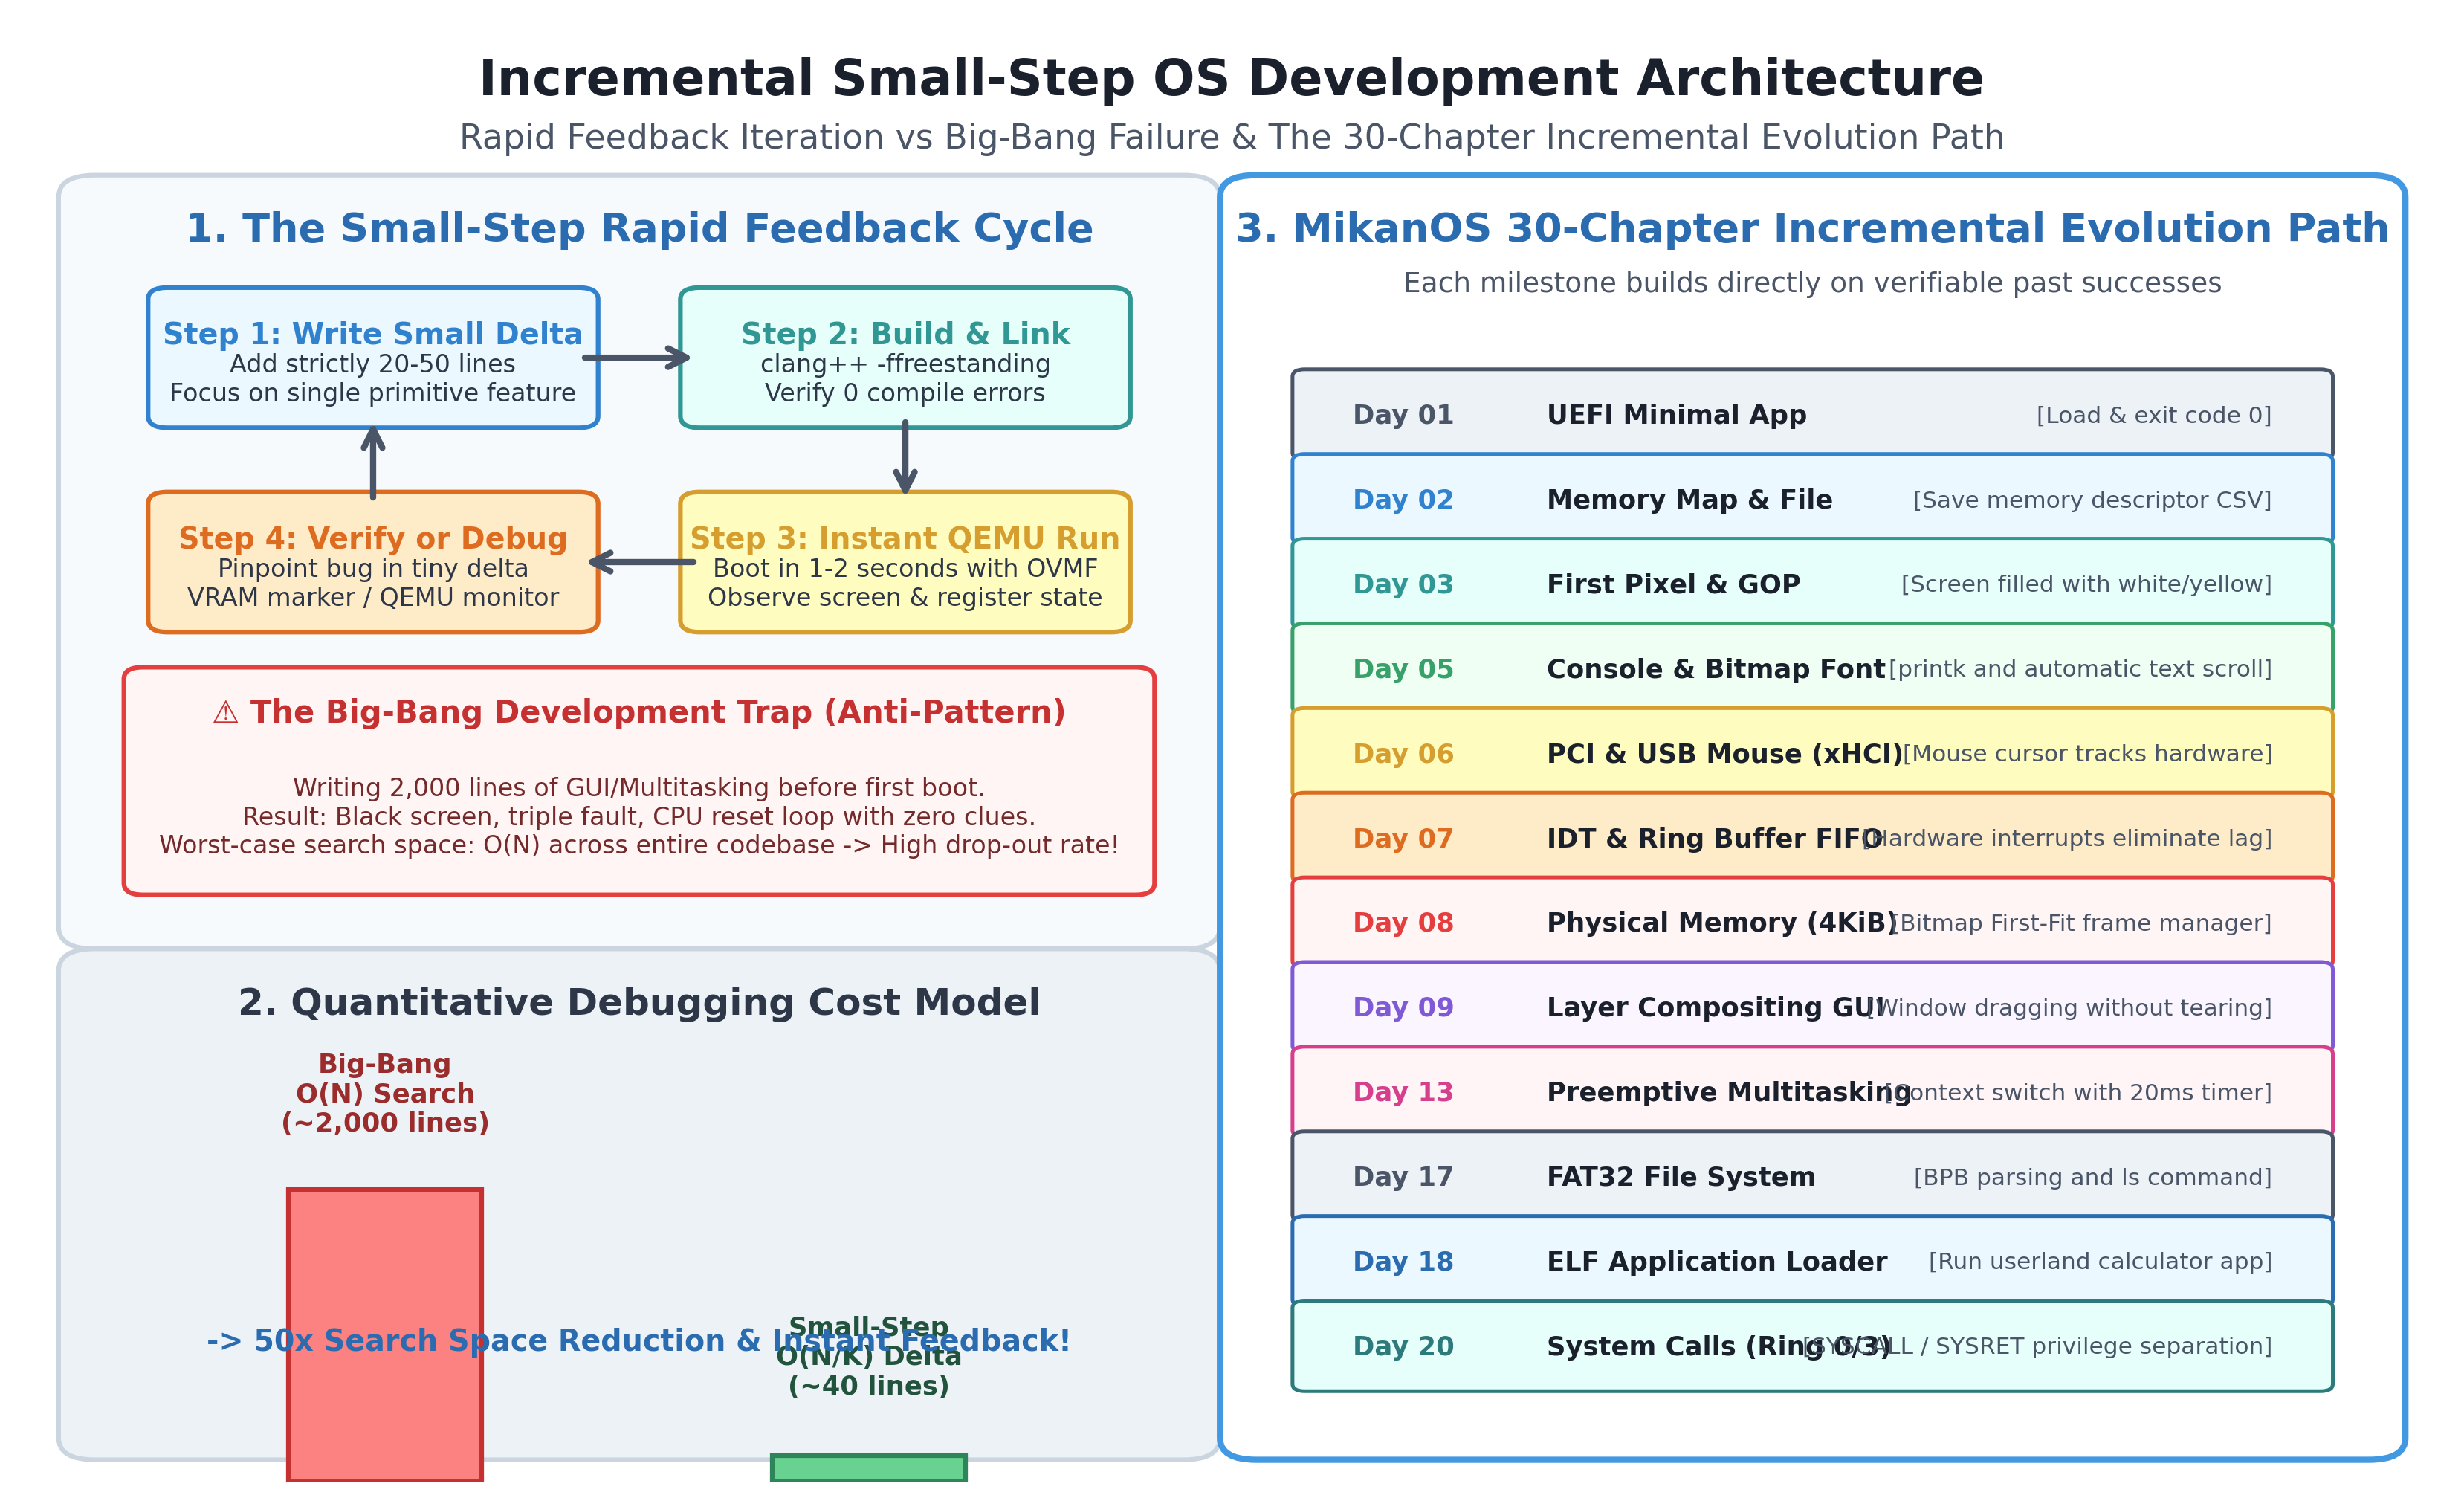

In [3]:
# 図版生成 1: スモールステップ開発サイクルと MikanOS 30章のインクリメンタル進化ロードマップ
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import Image, display

from common import setup_plot_style

setup_plot_style()
repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
result_dir = repo_root / "0" / "result"
result_dir.mkdir(parents=True, exist_ok=True)
out_path_1 = result_dir / "fig0_7_small_step_development_cycle.png"

fig, ax = plt.subplots(figsize=(14, 8.5), dpi=300)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

# Title
ax.text(50, 96, "Incremental Small-Step OS Development Architecture",
        fontsize=16, fontweight="bold", ha="center", va="center", color="#1a202c")
ax.text(50, 92, "Rapid Feedback Iteration vs Big-Bang Failure & The 30-Chapter Incremental Evolution Path",
        fontsize=11, ha="center", va="center", color="#4a5568")

# Panel A: Small-Step Iteration Loop vs Big-Bang Trap (Left side: x = 3 to 48)
rect_cycle = patches.FancyBboxPatch((3, 38), 45, 50, boxstyle="round,pad=1.5",
                                     fc="#f7fafc", ec="#cbd5e0", lw=1.5)
ax.add_patch(rect_cycle)
ax.text(25.5, 85, "1. The Small-Step Rapid Feedback Cycle", fontsize=13, fontweight="bold", ha="center", color="#2b6cb0")

# Steps in loop
steps = [
    ("Step 1: Write Small Delta", "Add strictly 20-50 lines\nFocus on single primitive feature", 6, 73, 17, 8, "#ebf8ff", "#3182ce"),
    ("Step 2: Build & Link", "clang++ -ffreestanding\nVerify 0 compile errors", 28, 73, 17, 8, "#e6fffa", "#319795"),
    ("Step 3: Instant QEMU Run", "Boot in 1-2 seconds with OVMF\nObserve screen & register state", 28, 59, 17, 8, "#fefcbf", "#d69e2e"),
    ("Step 4: Verify or Debug", "Pinpoint bug in tiny delta\nVRAM marker / QEMU monitor", 6, 59, 17, 8, "#feebc8", "#dd6b20"),
]

for title, desc, x, y, w, h, bg, border in steps:
    box = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.8", fc=bg, ec=border, lw=1.5)
    ax.add_patch(box)
    ax.text(x + w/2, y + h - 2.5, title, fontsize=9.5, fontweight="bold", ha="center", va="center", color=border)
    ax.text(x + w/2, y + 2.5, desc, fontsize=8, ha="center", va="center", color="#2d3748")

# Connective arrows
arrow_kwargs = dict(arrowstyle="->", lw=2, color="#4a5568", mutation_scale=15)
ax.annotate("", xy=(28, 77), xytext=(23, 77), arrowprops=arrow_kwargs)
ax.annotate("", xy=(36.5, 67), xytext=(36.5, 73), arrowprops=arrow_kwargs)
ax.annotate("", xy=(23, 63), xytext=(28, 63), arrowprops=arrow_kwargs)
ax.annotate("", xy=(14.5, 73), xytext=(14.5, 67), arrowprops=arrow_kwargs)

# Big-Bang Trap Warning Box
trap_box = patches.FancyBboxPatch((5, 41), 41, 14, boxstyle="round,pad=0.8", fc="#fff5f5", ec="#e53e3e", lw=1.5)
ax.add_patch(trap_box)
ax.text(25.5, 52, "⚠ The Big-Bang Development Trap (Anti-Pattern)", fontsize=10, fontweight="bold", ha="center", color="#c53030")
ax.text(25.5, 45.5, "Writing 2,000 lines of GUI/Multitasking before first boot.\nResult: Black screen, triple fault, CPU reset loop with zero clues.\nWorst-case search space: O(N) across entire codebase -> High drop-out rate!",
        fontsize=8, ha="center", va="center", color="#742a2a")

# Panel B: Search Space & Debugging Cost Comparison (Left bottom)
rect_cost = patches.FancyBboxPatch((3, 3), 45, 32, boxstyle="round,pad=1.5",
                                    fc="#edf2f7", ec="#cbd5e0", lw=1.5)
ax.add_patch(rect_cost)
ax.text(25.5, 32, "2. Quantitative Debugging Cost Model", fontsize=12, fontweight="bold", ha="center", color="#2d3748")

ax.bar(15, 20, width=8, color="#fc8181", edgecolor="#c53030", lw=1.5)
ax.bar(35, 1.8, width=8, color="#68d391", edgecolor="#2f855a", lw=1.5)
ax.text(15, 24, "Big-Bang\nO(N) Search\n(~2,000 lines)", fontsize=8.5, ha="center", fontweight="bold", color="#9b2c2c")
ax.text(35, 6, "Small-Step\nO(N/K) Delta\n(~40 lines)", fontsize=8.5, ha="center", fontweight="bold", color="#22543d")
ax.text(25.5, 9, "-> 50x Search Space Reduction & Instant Feedback!", fontsize=9.5, fontweight="bold", ha="center", color="#2b6cb0")

# Panel C: MikanOS Incremental Milestone Roadmap (Right side)
rect_roadmap = patches.FancyBboxPatch((51, 3), 46, 85, boxstyle="round,pad=1.5",
                                      fc="#ffffff", ec="#4299e1", lw=2)
ax.add_patch(rect_roadmap)
ax.text(74, 85, "3. MikanOS 30-Chapter Incremental Evolution Path", fontsize=13, fontweight="bold", ha="center", color="#2b6cb0")
ax.text(74, 81.5, "Each milestone builds directly on verifiable past successes", fontsize=9, ha="center", color="#4a5568")

milestones_vis = [
    ("Day 01", "UEFI Minimal App", "Load & exit code 0", "#4a5568", "#edf2f7"),
    ("Day 02", "Memory Map & File", "Save memory descriptor CSV", "#3182ce", "#ebf8ff"),
    ("Day 03", "First Pixel & GOP", "Screen filled with white/yellow", "#319795", "#e6fffa"),
    ("Day 05", "Console & Bitmap Font", "printk and automatic text scroll", "#38a169", "#f0fff4"),
    ("Day 06", "PCI & USB Mouse (xHCI)", "Mouse cursor tracks hardware", "#d69e2e", "#fefcbf"),
    ("Day 07", "IDT & Ring Buffer FIFO", "Hardware interrupts eliminate lag", "#dd6b20", "#feebc8"),
    ("Day 08", "Physical Memory (4KiB)", "Bitmap First-Fit frame manager", "#e53e3e", "#fff5f5"),
    ("Day 09", "Layer Compositing GUI", "Window dragging without tearing", "#805ad5", "#faf5ff"),
    ("Day 13", "Preemptive Multitasking", "Context switch with 20ms timer", "#d53f8c", "#fff5f7"),
    ("Day 17", "FAT32 File System", "BPB parsing and ls command", "#4a5568", "#edf2f7"),
    ("Day 18", "ELF Application Loader", "Run userland calculator app", "#2b6cb0", "#ebf8ff"),
    ("Day 20", "System Calls (Ring 0/3)", "SYSCALL / SYSRET privilege separation", "#2c7a7b", "#e6fffa"),
]

y_pos = 75
for tag, name, cue, color, bg in milestones_vis:
    m_box = patches.FancyBboxPatch((53, y_pos - 4.5), 42, 5.2, boxstyle="round,pad=0.5", fc=bg, ec=color, lw=1.2)
    ax.add_patch(m_box)
    ax.text(55, y_pos - 2, tag, fontsize=8.5, fontweight="bold", color=color, va="center")
    ax.text(63, y_pos - 2, name, fontsize=8.5, fontweight="bold", color="#1a202c", va="center")
    ax.text(93, y_pos - 2, f"[{cue}]", fontsize=7.5, color="#4a5568", ha="right", va="center")
    y_pos -= 5.8

plt.savefig(out_path_1, bbox_inches="tight", dpi=300)
plt.close()
display(Image(filename=str(out_path_1)))


### 5.2 図版 2: ベアメタル OS における5大デバッグ戦略体系図
標準出力（`printf`）が存在しない沈黙のベアメタル環境において、開発者が駆使する5大デバッグ手法（画面色塗り、CPU停止ループ、UARTシリアル通信、QEMUモニタ/GDB、二分探索）の原理・用途・技術詳細を体系的に整理しています。

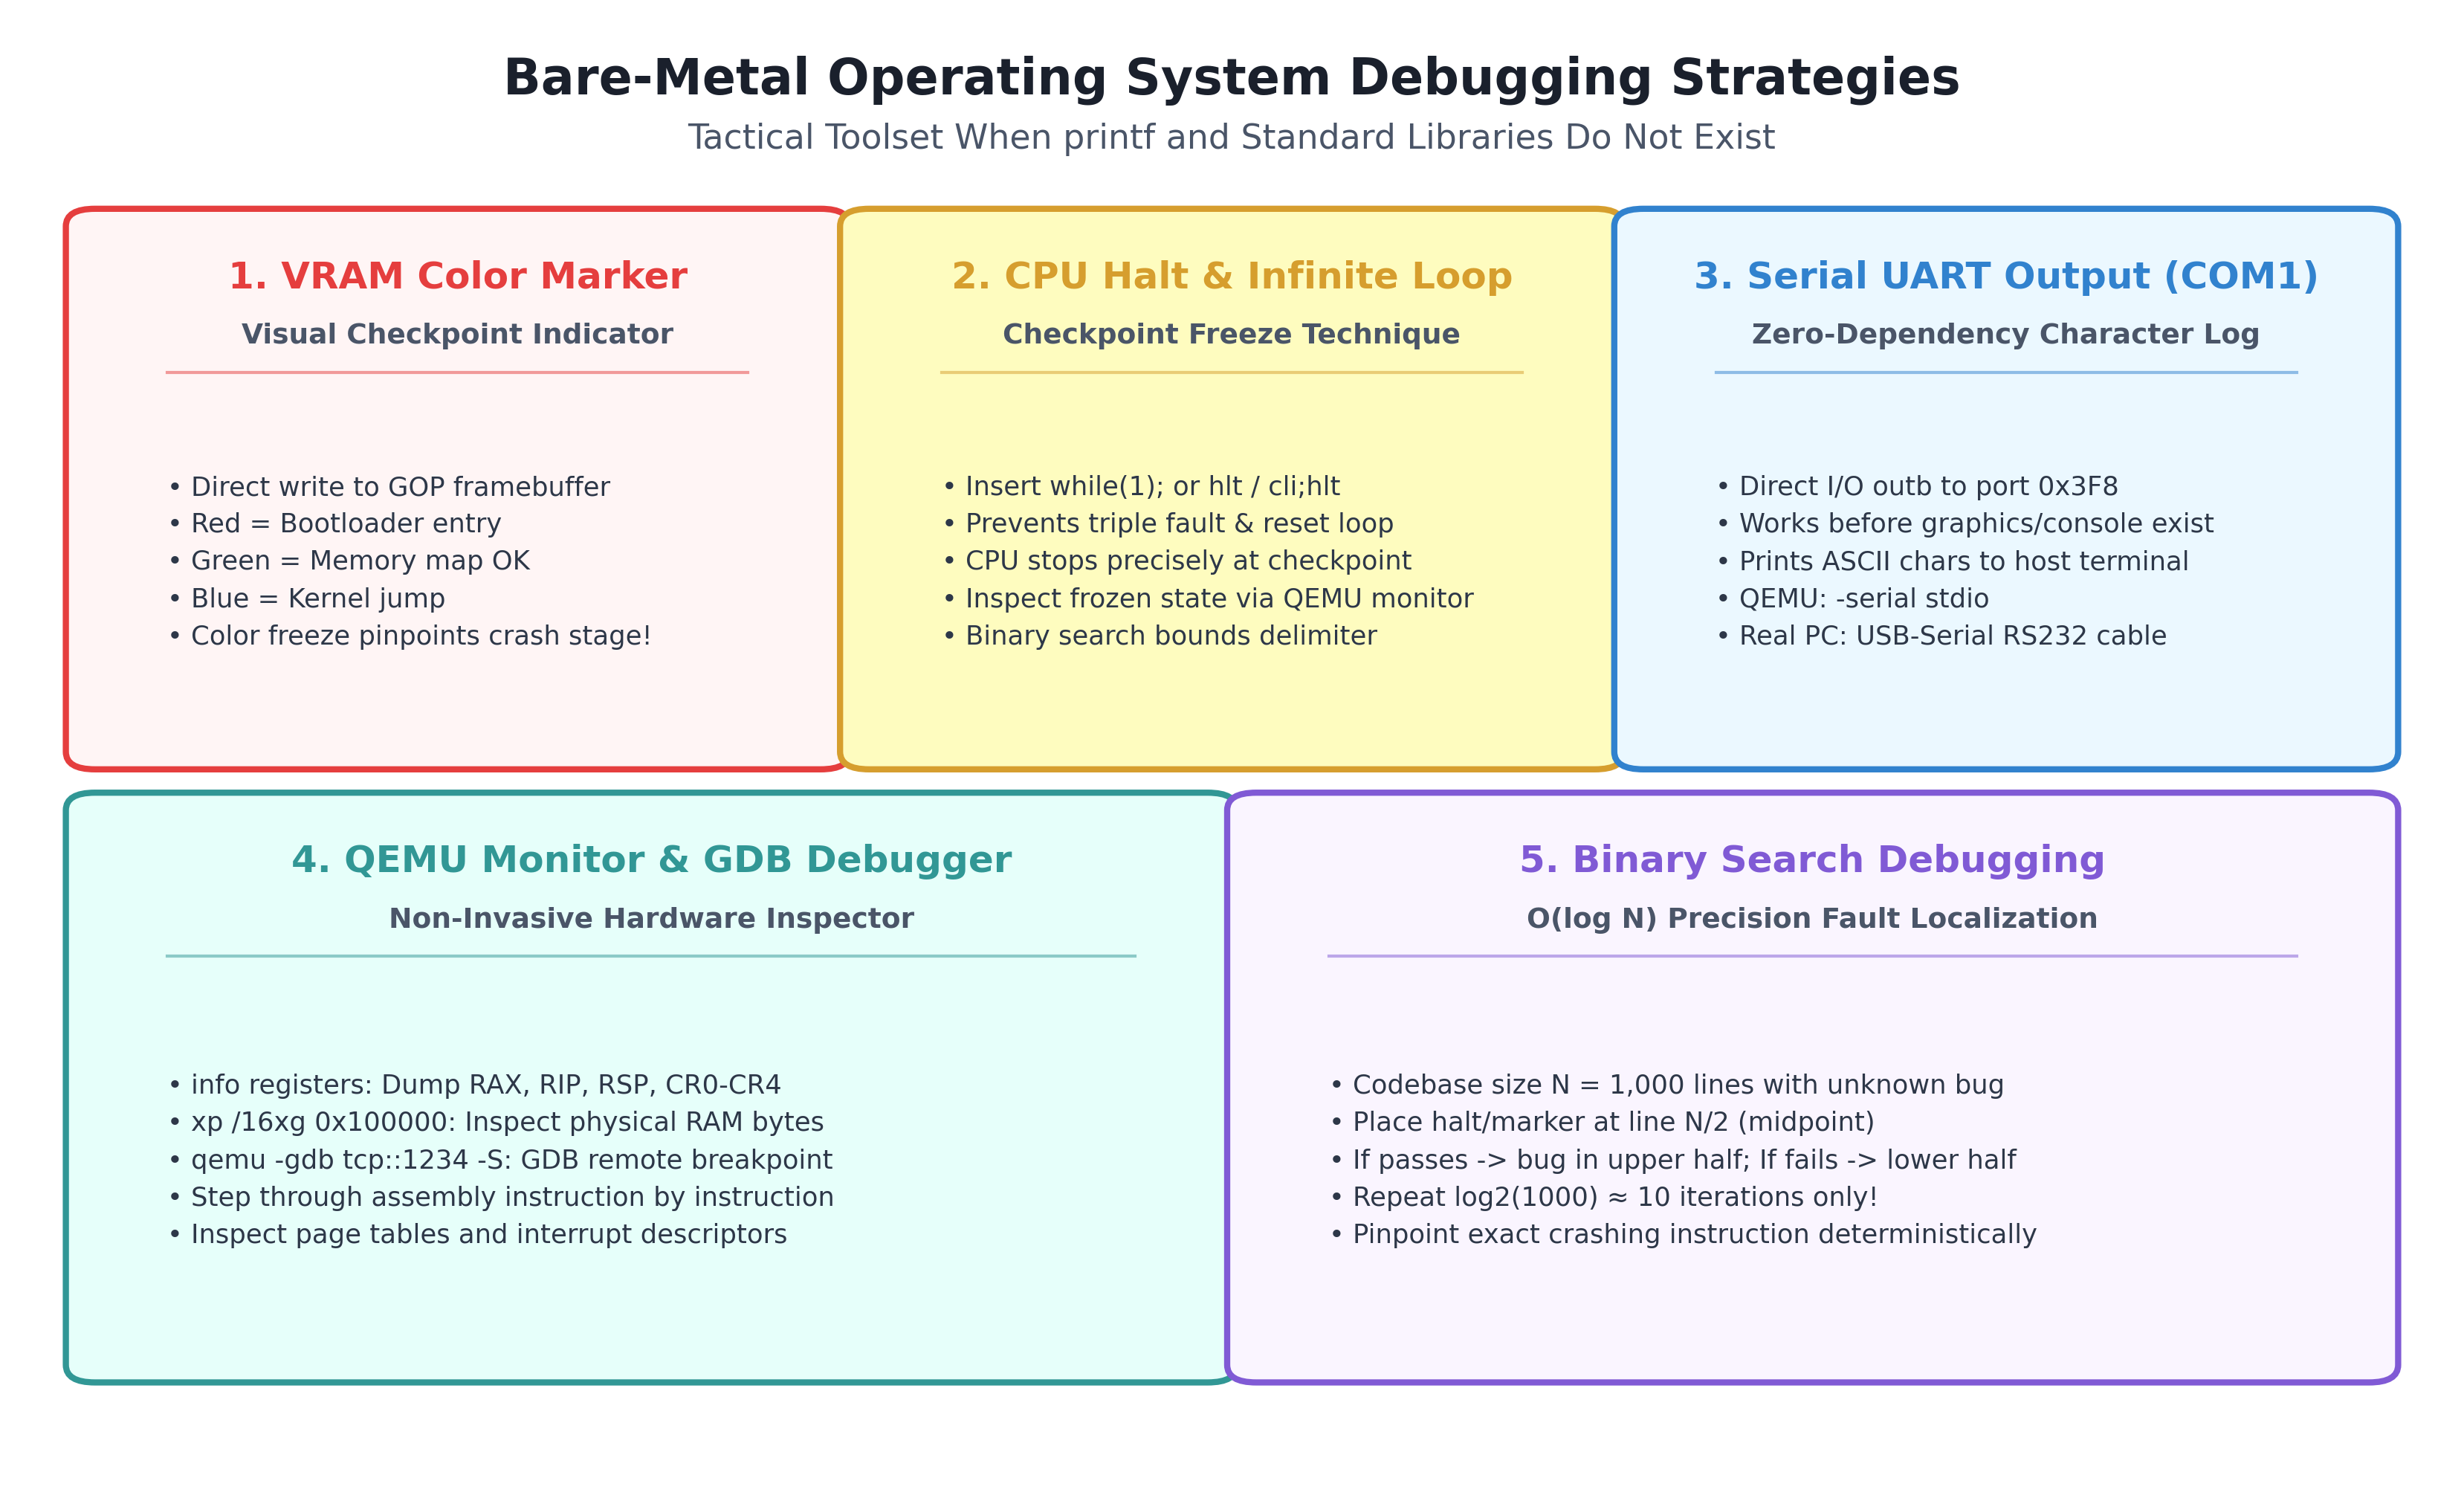

In [4]:
# 図版生成 2: ベアメタル OS における5大デバッグ戦略体系図
out_path_2 = result_dir / "fig0_8_os_debugging_strategies.png"

fig, ax = plt.subplots(figsize=(14, 8.5), dpi=300)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

# Title
ax.text(50, 96, "Bare-Metal Operating System Debugging Strategies",
        fontsize=16, fontweight="bold", ha="center", va="center", color="#1a202c")
ax.text(50, 92, "Tactical Toolset When printf and Standard Libraries Do Not Exist",
        fontsize=11, ha="center", va="center", color="#4a5568")

# 5 Debugging Strategies (Top 3 boxes: y=50 to 86, Bottom 2 boxes: y=8 to 44)
strategies = [
    ("1. VRAM Color Marker", "Visual Checkpoint Indicator",
     "• Direct write to GOP framebuffer\n• Red = Bootloader entry\n• Green = Memory map OK\n• Blue = Kernel jump\n• Color freeze pinpoints crash stage!",
     3, 50, 30, 36, "#fff5f5", "#e53e3e"),
    ("2. CPU Halt & Infinite Loop", "Checkpoint Freeze Technique",
     "• Insert while(1); or hlt / cli;hlt\n• Prevents triple fault & reset loop\n• CPU stops precisely at checkpoint\n• Inspect frozen state via QEMU monitor\n• Binary search bounds delimiter",
     35, 50, 30, 36, "#fefcbf", "#d69e2e"),
    ("3. Serial UART Output (COM1)", "Zero-Dependency Character Log",
     "• Direct I/O outb to port 0x3F8\n• Works before graphics/console exist\n• Prints ASCII chars to host terminal\n• QEMU: -serial stdio\n• Real PC: USB-Serial RS232 cable",
     67, 50, 30, 36, "#ebf8ff", "#3182ce"),
    ("4. QEMU Monitor & GDB Debugger", "Non-Invasive Hardware Inspector",
     "• info registers: Dump RAX, RIP, RSP, CR0-CR4\n• xp /16xg 0x100000: Inspect physical RAM bytes\n• qemu -gdb tcp::1234 -S: GDB remote breakpoint\n• Step through assembly instruction by instruction\n• Inspect page tables and interrupt descriptors",
     3, 8, 46, 38, "#e6fffa", "#319795"),
    ("5. Binary Search Debugging", "O(log N) Precision Fault Localization",
     "• Codebase size N = 1,000 lines with unknown bug\n• Place halt/marker at line N/2 (midpoint)\n• If passes -> bug in upper half; If fails -> lower half\n• Repeat log2(1000) ≈ 10 iterations only!\n• Pinpoint exact crashing instruction deterministically",
     51, 8, 46, 38, "#faf5ff", "#805ad5"),
]

for title, sub, desc, x, y, w, h, bg, border in strategies:
    box = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=1.2", fc=bg, ec=border, lw=2)
    ax.add_patch(box)
    ax.text(x + w/2, y + h - 3.5, title, fontsize=12, fontweight="bold", ha="center", va="center", color=border)
    ax.text(x + w/2, y + h - 7.5, sub, fontsize=9, fontweight="bold", ha="center", va="center", color="#4a5568")
    ax.plot([x + 3, x + w - 3], [y + h - 10, y + h - 10], color=border, lw=1, alpha=0.5)
    ax.text(x + 3, y + (h - 10)/2, desc, fontsize=8.5, ha="left", va="center", color="#2d3748", linespacing=1.6)

plt.savefig(out_path_2, bbox_inches="tight", dpi=300)
plt.close()
display(Image(filename=str(out_path_2)))


## 6. Python によるスモールステップ分析・デバッグシミュレーション

`common` モジュール（`SmallStepProgressTracker`, `BareMetalDebugSimulator`, `QemuVsHardwareComparator`）を活用し、以下の3つの検証実験をインタラクティブに行います：
1. **探索空間の定量比較**: ビッグバン開発 vs スモールステップ開発の探索行数とフィードバック遅延の数値比較
2. **二分探索デバッグの実証**: 120行の仮想カーネル初期化コードに潜むクラッシュ行（Line 42）を、二分探索でわずか7ステップで特定する過程の完全トレース
3. **QEMU vs 実機比較表**: 起動時間、デバッグ容易性、安全性、ハードウェア検証の多角的マトリクス

In [5]:
# Python によるスモールステップ分析・二分探索デバッグシミュレーション
from common import (
    BareMetalDebugSimulator,
    DevelopmentMethod,
    QemuVsHardwareComparator,
    SmallStepProgressTracker,
)

# 1. スモールステップ開発コストモデルの計算
tracker = SmallStepProgressTracker()
total_lines = tracker.total_cumulative_lines()
cost_bb = tracker.calculate_debugging_cost(total_lines, DevelopmentMethod.BIG_BANG)
cost_ss = tracker.calculate_debugging_cost(total_lines, DevelopmentMethod.SMALL_STEP)

print("=== [1] ビッグバン開発 vs スモールステップ開発の定量比較 ===")
print(f"総コード行数 (15マイルストーン累計): {total_lines} 行")
print(f"ビッグバン開発の最悪探索行数      : {cost_bb['worst_case_search_lines']:.0f} 行 (全体監査)")
print(f"スモールステップ開発の平均探索行数  : {cost_ss['worst_case_search_lines']:.1f} 行 (直前差分のみ)")
print(f"フィードバック遅延の比較          : {cost_bb['feedback_delay_days']} 日 vs {cost_ss['feedback_delay_days']} 日")
ratio = cost_bb['worst_case_search_lines'] / cost_ss['worst_case_search_lines']
print(f"-> スモールステップ開発により、バグ探索空間が約 {ratio:.1f} 倍に縮小！\n")

# 2. ベアメタル二分探索デバッグシミュレーション
sim = BareMetalDebugSimulator(total_lines=120, bug_line=42)
bsearch_steps = sim.locate_bug_by_binary_search()

print("=== [2] 二分探索によるクラッシュ行（Line 42）の特定トレース ===")
print("Step | 探索ウィンドウ [Low..High] | プローブ行 | 実行結果")
print("-----+---------------------------+------------+------------------")
for s in bsearch_steps:
    status = "PASS (正常通過 -> 後半へ)" if s.outcome == "PASS" else "CRASH (クラッシュ -> 前半へ)"
    print(f" {s.step_number:2d}  | [{s.low_line:3d} .. {s.high_line:3d}]         |    {s.probe_line:3d}     | {status}")

last_s = bsearch_steps[-1]
found_line = (last_s.probe_line + 1) if last_s.outcome == "PASS" else last_s.probe_line
print(f"\n-> {len(bsearch_steps)} 回のプローブで Line {found_line} のバグを特定完了！ (2^7 = 128 > 120)\n")

# 3. QEMU vs 実機 PC 比較マトリクス
print("=== [3] QEMU エミュレータ vs 実機 PC 比較マトリクス ===")
table = QemuVsHardwareComparator.get_comparison_table()
for feat in table:
    print(f"【{feat.category}】")
    print(f"  - QEMU+OVMF : {feat.qemu_ovmf}")
    print(f"  - 実機 PC   : {feat.real_hardware}")
    print(f"  - 開発への影響: {feat.impact_on_os_dev}\n")


=== [1] ビッグバン開発 vs スモールステップ開発の定量比較 ===
総コード行数 (15マイルストーン累計): 2371 行
ビッグバン開発の最悪探索行数      : 2371 行 (全体監査)
スモールステップ開発の平均探索行数  : 158.1 行 (直前差分のみ)
フィードバック遅延の比較          : 30.0 日 vs 0.1 日
-> スモールステップ開発により、バグ探索空間が約 15.0 倍に縮小！

=== [2] 二分探索によるクラッシュ行（Line 42）の特定トレース ===
Step | 探索ウィンドウ [Low..High] | プローブ行 | 実行結果
-----+---------------------------+------------+------------------
  1  | [  1 .. 120]         |     60     | CRASH (クラッシュ -> 前半へ)
  2  | [  1 ..  60]         |     30     | PASS (正常通過 -> 後半へ)
  3  | [ 31 ..  60]         |     45     | CRASH (クラッシュ -> 前半へ)
  4  | [ 31 ..  45]         |     38     | PASS (正常通過 -> 後半へ)
  5  | [ 39 ..  45]         |     42     | CRASH (クラッシュ -> 前半へ)
  6  | [ 39 ..  42]         |     40     | PASS (正常通過 -> 後半へ)
  7  | [ 41 ..  42]         |     41     | PASS (正常通過 -> 後半へ)

-> 7 回のプローブで Line 42 のバグを特定完了！ (2^7 = 128 > 120)

=== [3] QEMU エミュレータ vs 実機 PC 比較マトリクス ===
【起動・イテレーション時間】
  - QEMU+OVMF : 約 1〜2 秒（即座に再起動可能）
  - 実機 PC   : 約 30〜60 秒（PC再起動・USB認識待ち）
  - 開発への影響

## 7. まとめと次節への橋渡し

### 本節の重要ポイント
1. **スモールステップ開発（Small-Step Development）の徹底**:
   - OS自作における最大の挫折要因は「ビッグバン開発（数千行一気に書いて画面が真っ暗になること）」にある。
   - 常に「動く状態」をキープし、20〜50行（$\Delta N$）単位で前進することで、バグの探索空間を $1/50$ 以下に局所化できる。
2. **QEMU と実機のハイブリッド戦略**:
   - 1〜2秒で起動し、完全な可観測性（レジスタ・メモリダンプ、GDB）を持つ QEMU を開発の主軸にする。
   - 重要マイルストーン達成時に物理USBメモリで実機ブートし、「PCを支配した」という圧倒的感動と実機ハードウェア挙動を味わう。
3. **printf のない世界での5大デバッグ思考法**:
   - **VRAM色塗り**: 画面のフリーズ色で到達チェックポイントを視覚判定。
   - **CPU停止（`while(1);` / `cli; hlt`）**: 三重フォルト無限ループを防ぎ、特定行で安全に静止。
   - **シリアル通信（UART 0x3F8）**: 画面描画不要でホスト端末へ1バイトずつ文字ログ送出。
   - **QEMUモニタ & GDB**: レジスタ・物理メモリを非侵襲で検査。
   - **二分探索デバッグ**: $\lceil \log_2 N \rceil$ 回の試行で、巨大コードから原因命令を数学的・確定的に特定。

---

### 次節への橋渡し（0.5節 OS自作の全体像）
「どうやって楽しく、安全に、迷子にならずにOSを作るか」の心構えとデバッグ思考法が完全に整いました。

続く第0章の最終節 **「0.5 OS自作の全体像 (*Big Picture of MikanOS*)」** では、これから第1章〜第30章で構築していく MikanOS の全アーキテクチャ設計図を展開します。
- なぜレガシーBIOSではなく **64ビット UEFI** を採用したのか？
- なぜアセンブリやC言語単体ではなく **C++17/20 のオブジェクト指向・テンプレート** を導入するのか？
- ブートローダ、ピクセル描画、マウス入力、割り込み、4階層ページング、マルチタスク、ファイルシステム、システムコールがどのように一本の美しいパイプラインとして繋がっていくのか？

MikanOS の壮大な設計思想の全貌を明らかにします。準備ができたら、次のノートブックへ進みましょう！